# What to measure and why; the proxy test: what is a number for, and how do you tell the goal from its stand-in?

**Week 4, Monday, chapter 1 of 11, concept chapter 1 of 6.** The topic, in the curriculum's words: *What to measure and why; the proxy test*. Every number in this notebook is invented for the chapter and small enough to count by hand. It is read from a table the day's generator wrote to `data/`, and the code only confirms the count.

**Who needs the answer.** A school canteen's owner (invented), who cooks tomorrow's rice from today's count and pays the servers by it: a count that drifts from the plates wastes rice and money every day. After the break the same question reaches Uber's Hyderabad city head, whose scheme pays drivers on peak online hours.

**The questions on the way.**

1. What does the canteen's table hold?
2. What did tokens per plate do once the servers were paid per token?
3. How much rice did the owner cook for nobody, and what did it cost?
4. What is the proxy test, written as a rule a team can run?
5. Does a school bus driver's kilometres pass the test, in your turn?

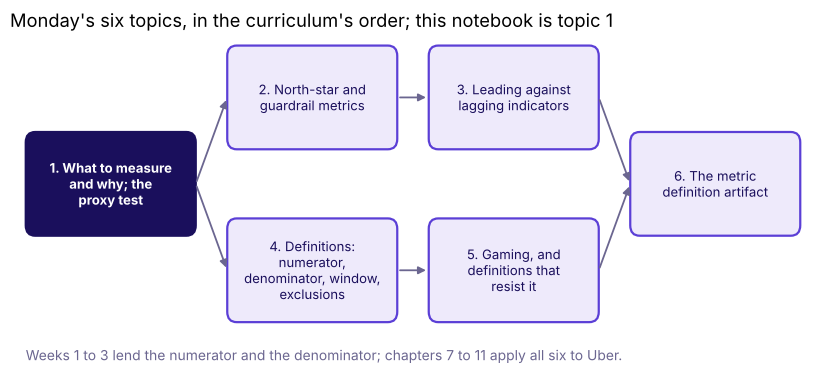

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

from matplotlib.patches import FancyBboxPatch, Patch

TOPICS = ["1. What to measure\nand why; the\nproxy test", "2. North-star and\nguardrail metrics",
          "3. Leading against\nlagging indicators", "4. Definitions:\nnumerator,\ndenominator, window,\nexclusions",
          "5. Gaming, and\ndefinitions that\nresist it", "6. The metric\ndefinition artifact"]
PLACE = [(1.6, 2.25), (4.8, 3.5), (8.0, 3.5), (4.8, 1.0), (8.0, 1.0), (11.2, 2.25)]
LINKS = [(0, 1), (1, 2), (0, 3), (3, 4), (2, 5), (4, 5)]


def topic_map(lit):
    """Monday's six topics in the curriculum's order, joined as the deck's concept map joins them."""
    fig, ax = plt.subplots(figsize=(10.4, 4.4))
    w, h = 2.7, 1.5
    for a, b in LINKS:
        (xa, ya), (xb, yb) = PLACE[a], PLACE[b]
        ax.annotate("", xy=(xb - w / 2, yb), xytext=(xa + w / 2, ya),
                    arrowprops={"arrowstyle": "-|>", "color": MUTED, "lw": 1.3})
    for i, ((x, y), label) in enumerate(zip(PLACE, TOPICS), start=1):
        on = i == lit
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.15",
                                    fc=INK if on else "#EEEAFB", ec=INK if on else VIOLET, lw=1.6))
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5, color="white" if on else INK,
                fontweight="bold" if on else "normal")
    ax.text(0.25, -0.3, "Weeks 1 to 3 lend the numerator and the denominator; chapters 7 to 11 apply all six to Uber.",
            fontsize=10, color=MUTED)
    ax.set_xlim(0, 12.8)
    ax.set_ylim(-0.5, 4.4)
    ax.axis("off")
    ax.set_title(f"Monday's six topics, in the curriculum's order; this notebook is topic {lit}", loc="left")
    plt.show()

topic_map(1)

## What does the canteen's table hold?

A **metric** is a number a person watches in order to decide something: how much rice to cook,
whom to pay, whether to keep a scheme. A **target** is a metric with a value somebody is asked to
hit, and a person paid on a target works to hit it. The canteen (invented) hands each diner a
token with every plate, because tokens are easy to count and plates are not, and the owner reads
today's tokens to decide tomorrow's rice. From day 6 the servers are paid per token handed out.

This cell loads the ten days and prints every row.

In [2]:
days = pd.read_csv("../data/C2_W04_D01_canteen_days_STUDENT.csv")
print("Ten days at a school canteen, every number invented for this chapter:")
print(days.to_string(index=False))
check("ten days, with 200 plates served on every one", len(days) == 10 and (days["plates"] == 200).all())

Ten days at a school canteen, every number invented for this chapter:
 day servers_paid_per_token  tokens  plates
   1                     no     200     200
   2                     no     200     200
   3                     no     200     200
   4                     no     200     200
   5                     no     200     200
   6                    yes     400     200
   7                    yes     400     200
   8                    yes     400     200
   9                    yes     400     200
  10                    yes     400     200
PASS ten days, with 200 plates served on every one


## What did tokens per plate do once pay followed tokens?

**Predict before you run.** From day 6, what does tokens per plate do?

a) It stays at 1.0, since the plates did not change.
b) It rises to 2.0, since every plate now carries two tokens.
c) It falls to 0.5, since the servers are busier.
d) It cannot be told without the menu.

The next cell counts by hand first, one line per step, with numbers read off the table above;
then it counts every day by code and checks that the two agree. The owner cooks 150 g of rice a
plate and buys rice at Rs 50 a kg, both invented.

In [3]:
# By hand, one line per step, from the table above
hand_day1 = 200 / 200                            # tokens per plate before pay followed tokens: 1.0
hand_day6 = 400 / 200                            # tokens per plate on the first paid day: 2.0
hand_cooked = 400 * 0.15                         # kg of rice cooked from day 6's tokens: 60
hand_eaten = 200 * 0.15                          # kg the 200 diners eat: 30
hand_waste_rs = (hand_cooked - hand_eaten) * 50  # rupees of rice thrown away that day: 1,500

# By code, on every day of the table
days["per_plate"] = days["tokens"] / days["plates"]
days["rice_kg"] = days["tokens"] * 0.15          # what the owner cooks from tokens
days["eaten_kg"] = days["plates"] * 0.15         # what the diners eat
days["waste_rs"] = (days["rice_kg"] - days["eaten_kg"]) * 50
print(days[["day", "servers_paid_per_token", "per_plate", "rice_kg", "eaten_kg", "waste_rs"]].to_string(index=False))
check("hand and code agree: tokens per plate 1.0 on day 1 and 2.0 on day 6",
      (days.loc[0, "per_plate"], days.loc[5, "per_plate"]) == (hand_day1, hand_day6))
check("hand and code agree: Rs 1,500 of rice thrown away on day 6", days.loc[5, "waste_rs"] == hand_waste_rs)

 day servers_paid_per_token  per_plate  rice_kg  eaten_kg  waste_rs
   1                     no        1.0     30.0      30.0       0.0
   2                     no        1.0     30.0      30.0       0.0
   3                     no        1.0     30.0      30.0       0.0
   4                     no        1.0     30.0      30.0       0.0
   5                     no        1.0     30.0      30.0       0.0
   6                    yes        2.0     60.0      30.0    1500.0
   7                    yes        2.0     60.0      30.0    1500.0
   8                    yes        2.0     60.0      30.0    1500.0
   9                    yes        2.0     60.0      30.0    1500.0
  10                    yes        2.0     60.0      30.0    1500.0
PASS hand and code agree: tokens per plate 1.0 on day 1 and 2.0 on day 6
PASS hand and code agree: Rs 1,500 of rice thrown away on day 6


**What happened.** The answer is b: tokens per plate went from 1.0 to 2.0 on day 6 and not one
more diner ate. The plausible wrong reading is the owner's: tokens up 100 percent read as diners
up 100 percent, so 60 kg of rice is cooked for 30 kg of eating. The check that catches it is the
plates column, which the pay rule never touched; the fix is to cook and to pay on plates.

## What does the drift look like, day by day?

This cell draws tokens and plates side by side for the ten days, with the day the pay rule
changed marked by the dashed line.

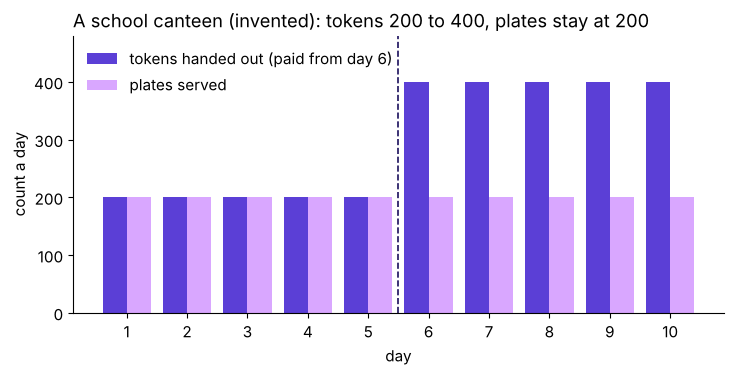

In [4]:
fig, ax = plt.subplots(figsize=(8.4, 3.6))
ax.bar(days["day"] - 0.2, days["tokens"], width=0.4, color=VIOLET, label="tokens handed out (paid from day 6)")
ax.bar(days["day"] + 0.2, days["plates"], width=0.4, color=LAV, label="plates served")
ax.axvline(5.5, color=INK, linestyle="--", lw=1.2)
ax.set_xticks(days["day"])
ax.set_ylim(0, 480)
ax.set_xlabel("day")
ax.set_ylabel("count a day")
ax.legend(frameon=False, loc="upper left")
ax.set_title("A school canteen (invented): tokens 200 to 400, plates stay at 200", loc="left")
plt.show()

The tokens stood in for plates until the servers were paid on them; from day 6 the paid number
doubled and the plates stayed flat.

## How much did the drift cost the owner?

**Predict before you run.** Over the five paid days, how much does the owner spend on rice that
nobody eats? a) Rs 1,500; b) Rs 3,000; c) Rs 7,500; d) nothing, since the rice is eaten later.

This cell draws each day's waste and its running total.

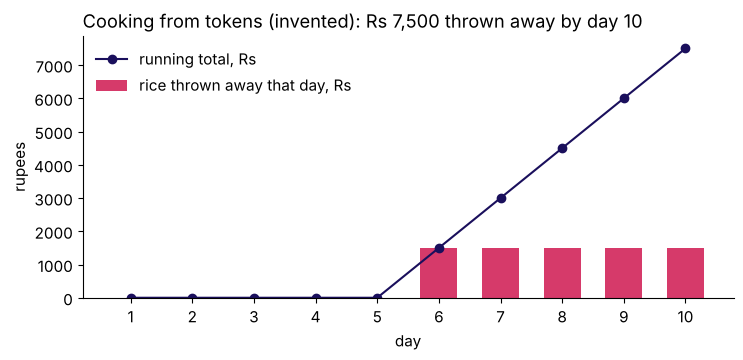

PASS Rs 7,500 thrown away over the five paid days and nothing before


In [5]:
days["waste_so_far_rs"] = days["waste_rs"].cumsum()
fig, ax = plt.subplots(figsize=(8.4, 3.4))
ax.bar(days["day"], days["waste_rs"], width=0.6, color=ROSE, label="rice thrown away that day, Rs")
ax.plot(days["day"], days["waste_so_far_rs"], marker="o", color=INK, label="running total, Rs")
ax.set_xticks(days["day"])
ax.set_xlabel("day")
ax.set_ylabel("rupees")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Cooking from tokens (invented): Rs 7,500 thrown away by day 10", loc="left")
plt.show()
check("Rs 7,500 thrown away over the five paid days and nothing before",
      days["waste_so_far_rs"].iloc[-1] == 7500 and (days.loc[:4, "waste_rs"] == 0).all())

**What happened.** The answer is c: Rs 1,500 on each of days 6 to 10, Rs 7,500 in all, and at
that pace a month of 30 paid days throws away Rs 45,000. Nobody was dishonest: the servers did
what the pay rule paid for.

## What is the proxy test, written as a rule a team can run?

A **proxy** is a number that stands in for the thing somebody wants: tokens stand in for plates,
and plates stand in for children fed. Named last: the **proxy test** asks whether a team could
hit this number while the thing it stands for got worse or stayed the same. The curriculum row
puts it in one line: if a department could hit the number while the business got worse, the
number is a proxy that has drifted. Any target bends behaviour toward itself.

This cell writes the test as a short function of two columns, the paid number and the wanted
one, compared on the first day and the last. It runs the test on all ten days, then on days 1
to 5 alone, before the pay rule.

In [6]:
def drifted(paid, wanted):
    """The proxy test failed: the paid number rose while the number it stands for did not."""
    return bool(paid.iloc[-1] > paid.iloc[0] and wanted.iloc[-1] <= wanted.iloc[0])

before = days[days["day"] <= 5]
print("tokens against plates, all ten days:", drifted(days["tokens"], days["plates"]))
print("tokens against plates, days 1 to 5:", drifted(before["tokens"], before["plates"]))
check("tokens fail the proxy test once pay follows them", drifted(days["tokens"], days["plates"]))
check("on days 1 to 5 tokens tracked plates, so the test passes", not drifted(before["tokens"], before["plates"]))

tokens against plates, all ten days: True
tokens against plates, days 1 to 5: False
PASS tokens fail the proxy test once pay follows them
PASS on days 1 to 5 tokens tracked plates, so the test passes


### Your turn: does a school bus driver's kilometres pass the proxy test?

The same school (invented) runs a bus that drops 30 children home every day. From day 6 its
driver is paid per kilometre logged. The table `../data/C2_W04_D01_school_bus_days_STUDENT.csv`
holds the ten days, with the columns `day`, `driver_paid_per_km`, `km_logged` and
`children_dropped_home`. In the empty cell below, fill the two blanks and run it:

```python
bus = pd.read_csv("../data/C2_W04_D01_school_bus_days_STUDENT.csv")
km_per_child = bus["km_logged"].iloc[-1] / bus["children_dropped_home"].iloc[-1]   # day 10
bus_drifted = drifted(bus[____], bus[____])   # the paid column first, then the wanted one
```

Then run the check under it, which compares your two answers with the reference and shows the
reference only once your answers exist.

In [7]:
mine = (globals().get("km_per_child"), globals().get("bus_drifted"))
if None in mine:
    print("Store km_per_child and bus_drifted in the empty cell above, then run this cell again.")
else:
    ref = pd.read_csv("../data/C2_W04_D01_school_bus_days_STUDENT.csv")
    ref_km = ref["km_logged"].iloc[-1] / ref["children_dropped_home"].iloc[-1]
    ref_drifted = drifted(ref["km_logged"], ref["children_dropped_home"])
    print(f"reference: {ref_km:.2f} km a child, drifted {ref_drifted}; yours: {mine[0]:.2f}, {mine[1]}")
    print("matches" if abs(mine[0] - ref_km) <= 0.005 and mine[1] == ref_drifted else "not yet: which column is paid?")

Store km_per_child and bus_drifted in the empty cell above, then run this cell again.


## What does chapter 1 leave?

1. The canteen's ten days (invented): 200 plates every day, 200 tokens a day before pay followed
   tokens and 400 after.
2. Tokens per plate went from 1.0 to 2.0 once the servers were paid per token.
3. Cooking from tokens threw away 30 kg of rice a day, Rs 1,500, and Rs 7,500 over five paid days.
4. The proxy test is the function `drifted(paid, wanted)`: the paid number rose while the thing
   it stands for did not.
5. Your turn asked the same of the bus driver's kilometres, paid per kilometre logged.

**The rules.**

- Name the decision a number feeds before you count it.
- A proxy stands in for the thing wanted, and nearly every number on a dashboard is one.
- Before anyone is paid on a number, ask whether a team could raise it while the goal got worse.
- Any target bends behaviour toward itself, so read a paid number beside the thing it stands for.

**In the interview.** [S] How would you measure the success of a new feature? ([S] marks a staple asked everywhere, [F] one frequent in GCC and product screens and [D] a differentiator: the curriculum's own calibration for early-career candidates in India.) A hire-grade
answer starts from what the feature is for and names a number that cannot rise while that thing
gets worse.

**Where it goes next.** Notebook 02 adds the second number that must not fall while the first
rises. After the break, `C2_W04_D01_07_proxy_test_on_twelve_rows_STUDENT.ipynb` runs the same
test on six Uber drivers, whose peak online hours count an hour whenever the driver app is open.